
# SaaS Churn Prediction & Diagnosis

**Business questions:**
1. What's our actual logo and revenue (MRR) churn, and which segments —
   plan tier, contract type — are driving it?
2. Can we predict, ahead of time, which currently-active accounts are at
   the highest risk of churning — and which behaviors actually drive that
   risk, so Customer Success knows where to intervene?

**Tools:** SQL (window functions for rolling engagement features), Python
(`scikit-learn` for logistic regression + random forest, `scipy` for
significance), Plotly for a churn-risk dashboard.

**Dataset:** 24 months (2024-01–2025-12) of synthetic B2B SaaS subscription
+ monthly usage data for 2,600 accounts across 3 plan tiers and 2 contract
types. `customers` holds one row per account (plan, contract, churn
outcome); `usage_monthly` holds monthly logins, active users, feature
adoption, and support tickets per account.


In [1]:

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

conn = sqlite3.connect("../data/churn.db")
def run_sql(path):
    with open(path) as f:
        return pd.read_sql_query(f.read(), conn)

customers = pd.read_sql_query("SELECT * FROM customers", conn)
print(f"{len(customers):,} accounts | overall churn rate: {customers.churned.mean():.1%}")


2,600 accounts | overall churn rate: 25.8%


## 1. Churn Rate by Plan Tier & Contract Type (logo vs. MRR-weighted)

In [2]:

churn_rates = run_sql("../sql/01_churn_rates.sql")
churn_rates


,plan_tier,contract_type,total_accounts,churned_accounts,logo_churn_rate_pct,total_mrr,churned_mrr,mrr_churn_rate_pct
0,Starter,Monthly,642,325,50.6,78314.15,39718.28,50.7
1,Growth,Monthly,550,160,29.1,301669.05,89168.59,29.6
2,Enterprise,Monthly,225,43,19.1,616100.89,113395.17,18.4
3,Starter,Annual,567,97,17.1,70325.90,11862.49,16.9
4,Growth,Annual,441,38,8.6,248990.67,21149.87,8.5
5,Enterprise,Annual,175,8,4.6,465688.36,24931.93,5.4


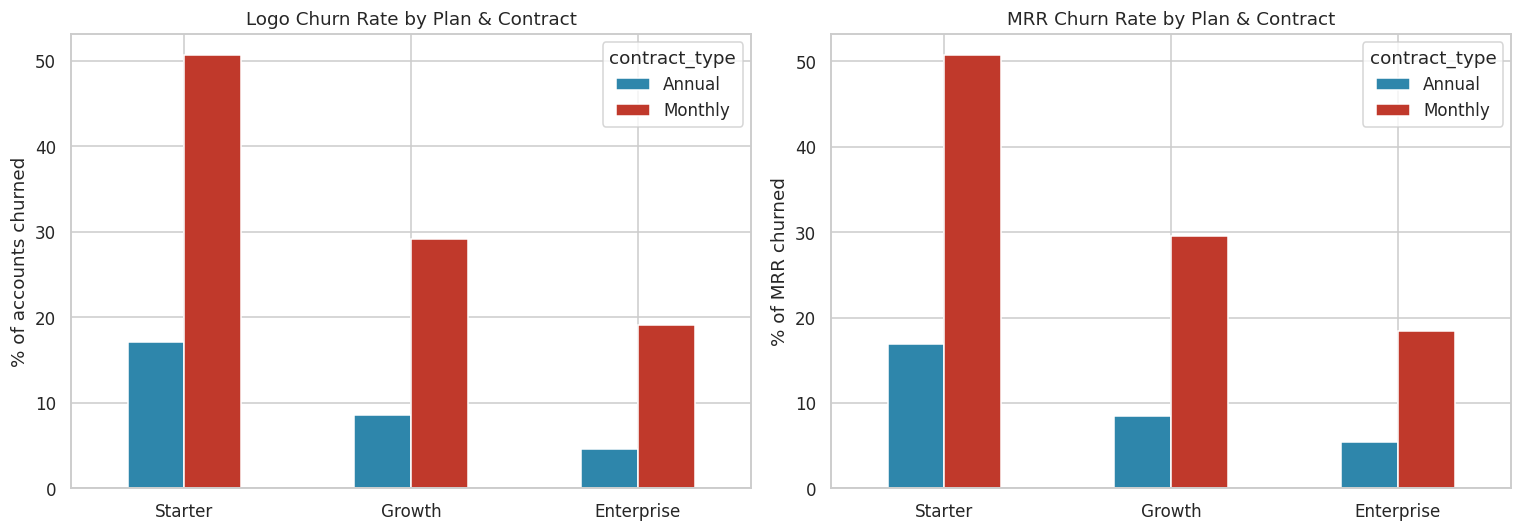

In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14,5))
pivot_logo = churn_rates.pivot(index="plan_tier", columns="contract_type", values="logo_churn_rate_pct").loc[["Starter","Growth","Enterprise"]]
pivot_mrr = churn_rates.pivot(index="plan_tier", columns="contract_type", values="mrr_churn_rate_pct").loc[["Starter","Growth","Enterprise"]]
pivot_logo.plot(kind="bar", ax=axes[0], color=["#2E86AB","#C0392B"])
axes[0].set_title("Logo Churn Rate by Plan & Contract")
axes[0].set_ylabel("% of accounts churned")
pivot_mrr.plot(kind="bar", ax=axes[1], color=["#2E86AB","#C0392B"])
axes[1].set_title("MRR Churn Rate by Plan & Contract")
axes[1].set_ylabel("% of MRR churned")
for ax in axes:
    ax.set_xlabel(""); plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig("../dashboard/churn_by_segment.png", dpi=150)
plt.show()


**Finding:** Starter/Monthly is the highest-risk segment on both logo and
MRR churn — annual contracts cut churn roughly 2-3x within every plan
tier, consistent with the well-known SaaS pattern that annual commitment
reduces switching. This alone suggests a lever: incentivizing annual
upgrades on Starter/Growth is likely higher-leverage than a general
retention campaign.

## 2. Monthly Churn Trend

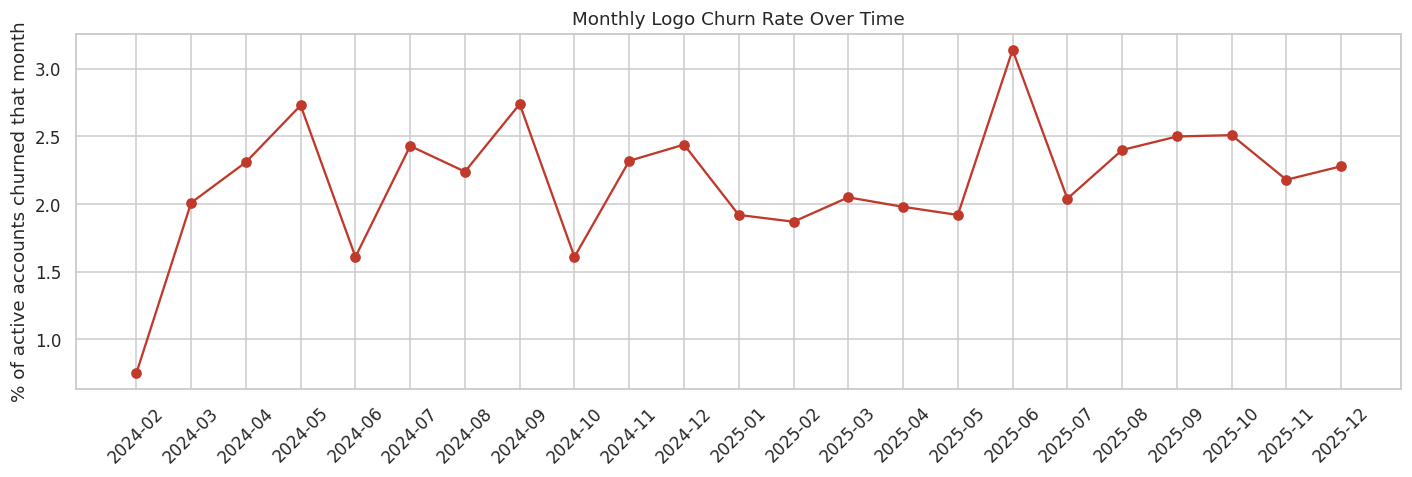

In [4]:

trend = run_sql("../sql/03_monthly_churn_trend.sql")
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(trend.month, trend.monthly_logo_churn_rate_pct, marker="o", color="#C0392B")
ax.set_title("Monthly Logo Churn Rate Over Time")
ax.set_ylabel("% of active accounts churned that month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../dashboard/churn_trend.png", dpi=150)
plt.show()


## 3. Feature Engineering (SQL window functions)

Using `sql/02_feature_engineering.sql` — trailing 3-month rolling login average, login trend %, and trailing support ticket count, computed per account **as of the month before churn** (for churned accounts) or **their latest month** (for active accounts), so the model predicts churn ahead of time rather than diagnosing it after the fact.

In [5]:

snapshot = run_sql("../sql/02_feature_engineering.sql")
print(snapshot.shape)
snapshot.head()


(2600, 14)


,customer_id,plan_tier,contract_type,region,industry,nps_score,initial_mrr,churned,tenure_months_at_snapshot,logins,logins_3mo_avg,login_trend_pct_3mo,tickets_trailing_3mo,features_used
0,ACCT9000,Starter,Monthly,APAC,Healthcare,38.0,50.09,0,9,48.9,50.066667,-4.3,6,4
1,ACCT9001,Growth,Monthly,North America,Retail/E-comm,NaN,302.31,0,15,93.5,89.833333,3.2,19,5
2,ACCT9002,Growth,Monthly,EMEA,Media,15.0,810.43,1,19,132.5,112.866667,17.9,17,6
3,ACCT9003,Starter,Monthly,North America,Retail/E-comm,23.0,195.16,0,10,45.2,42.500000,31.8,8,3
4,ACCT9004,Starter,Monthly,North America,Manufacturing,51.0,67.17,0,19,58.2,54.200000,57.3,41,1


## 4. Preparing the Modeling Dataset

In [6]:

df = snapshot.copy()

# Missing-data handling: NPS is missing for ~35% of accounts (realistic survey
# non-response). We impute with the median AND keep a missingness flag, since
# non-response itself can carry signal (silent, disengaged accounts are less
# likely to answer an NPS survey).
df["nps_missing"] = df["nps_score"].isna().astype(int)
df["nps_score"] = df["nps_score"].fillna(df["nps_score"].median())
df["login_trend_pct_3mo"] = df["login_trend_pct_3mo"].fillna(0)  # no 3mo history yet -> assume flat

cat_cols = ["plan_tier", "contract_type", "region"]
df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True)

feature_cols = [c for c in df_model.columns if c not in
                ["customer_id", "industry", "churned"]]
X = df_model[feature_cols]
y = df_model["churned"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}, churn rate train/test: {y_train.mean():.3f}/{y_test.mean():.3f}")


Train: (1950, 15), Test: (650, 15), churn rate train/test: 0.258/0.258


## 5. Model 1 — Logistic Regression (interpretable baseline)

In [7]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred_proba_lr = logreg.predict_proba(X_test_scaled)[:, 1]
auc_lr = roc_auc_score(y_test, y_pred_proba_lr)
print(f"Logistic Regression AUC: {auc_lr:.3f}")
print(classification_report(y_test, logreg.predict(X_test_scaled)))


Logistic Regression AUC: 0.849
              precision    recall  f1-score   support

           0       0.91      0.74      0.82       482
           1       0.52      0.80      0.63       168

    accuracy                           0.76       650
   macro avg       0.72      0.77      0.72       650
weighted avg       0.81      0.76      0.77       650



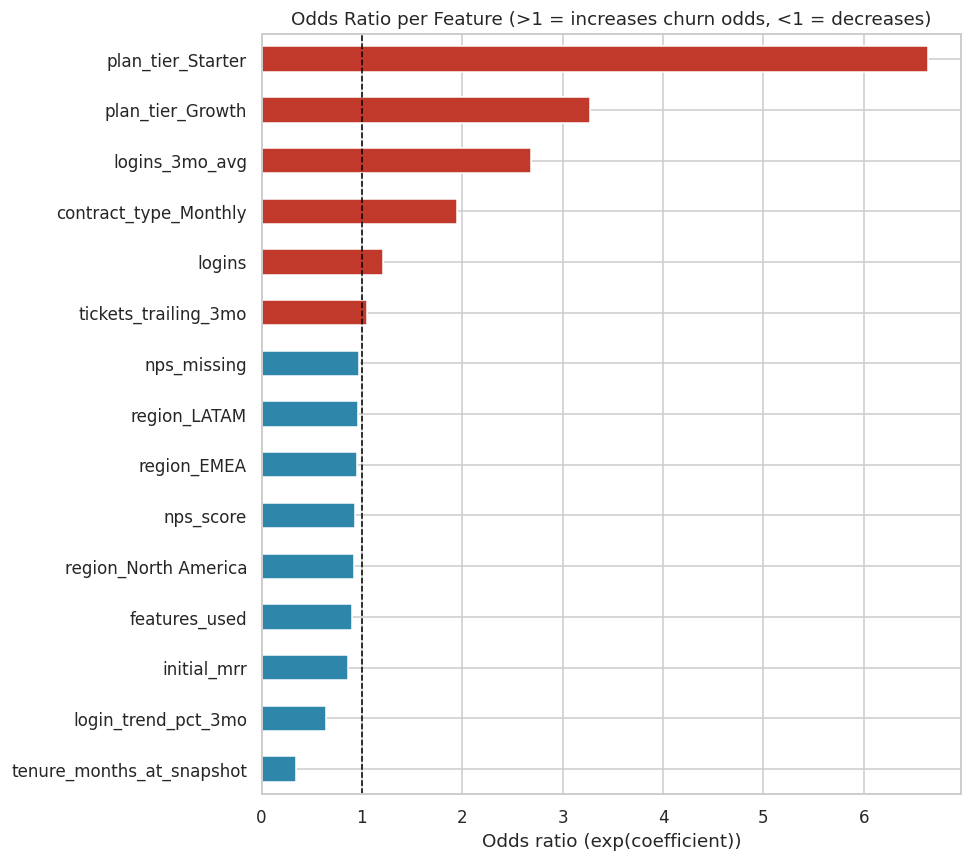

In [8]:

# Odds ratios -- the interpretability payoff of logistic regression: how much
# does each feature multiply churn odds by, holding others constant?
coefs = pd.Series(logreg.coef_[0], index=feature_cols).sort_values()
odds_ratios = np.exp(coefs)

fig, ax = plt.subplots(figsize=(9, 8))
odds_ratios.plot(kind="barh", ax=ax, color=["#C0392B" if v > 1 else "#2E86AB" for v in odds_ratios])
ax.axvline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_title("Odds Ratio per Feature (>1 = increases churn odds, <1 = decreases)")
ax.set_xlabel("Odds ratio (exp(coefficient))")
plt.tight_layout()
plt.savefig("../dashboard/odds_ratios.png", dpi=150)
plt.show()


## 6. Model 2 — Random Forest (captures non-linear interactions)

In [9]:

rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=15,
                             class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)
y_pred_proba_rf = rf.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
print(f"Random Forest AUC: {auc_rf:.3f}")
print(classification_report(y_test, rf.predict(X_test)))


Random Forest AUC: 0.859
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       482
           1       0.66      0.65      0.65       168

    accuracy                           0.82       650
   macro avg       0.77      0.77      0.77       650
weighted avg       0.82      0.82      0.82       650



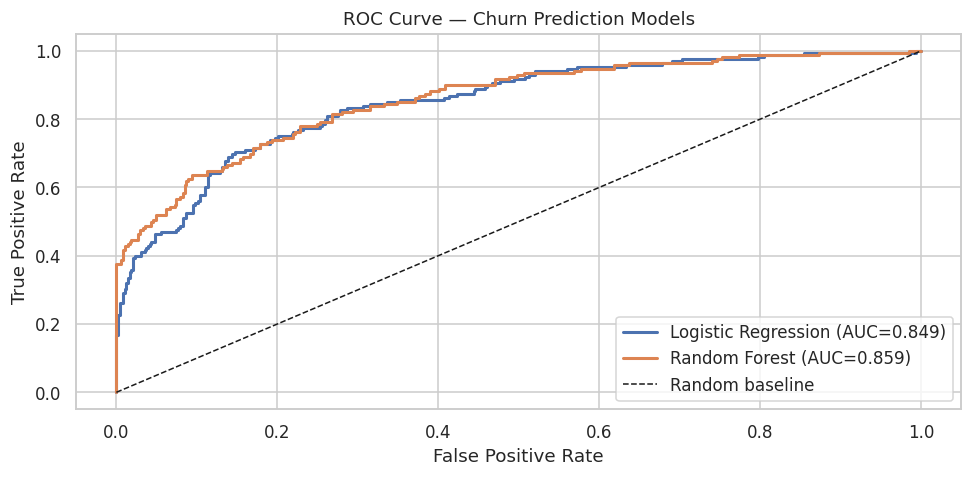

In [10]:

fig, ax = plt.subplots(figsize=(9,4.5))
for name, proba in [("Logistic Regression", y_pred_proba_lr), ("Random Forest", y_pred_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", linewidth=2)
ax.plot([0,1],[0,1], "k--", linewidth=1, label="Random baseline")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Churn Prediction Models")
ax.legend()
plt.tight_layout()
plt.savefig("../dashboard/roc_curve.png", dpi=150)
plt.show()


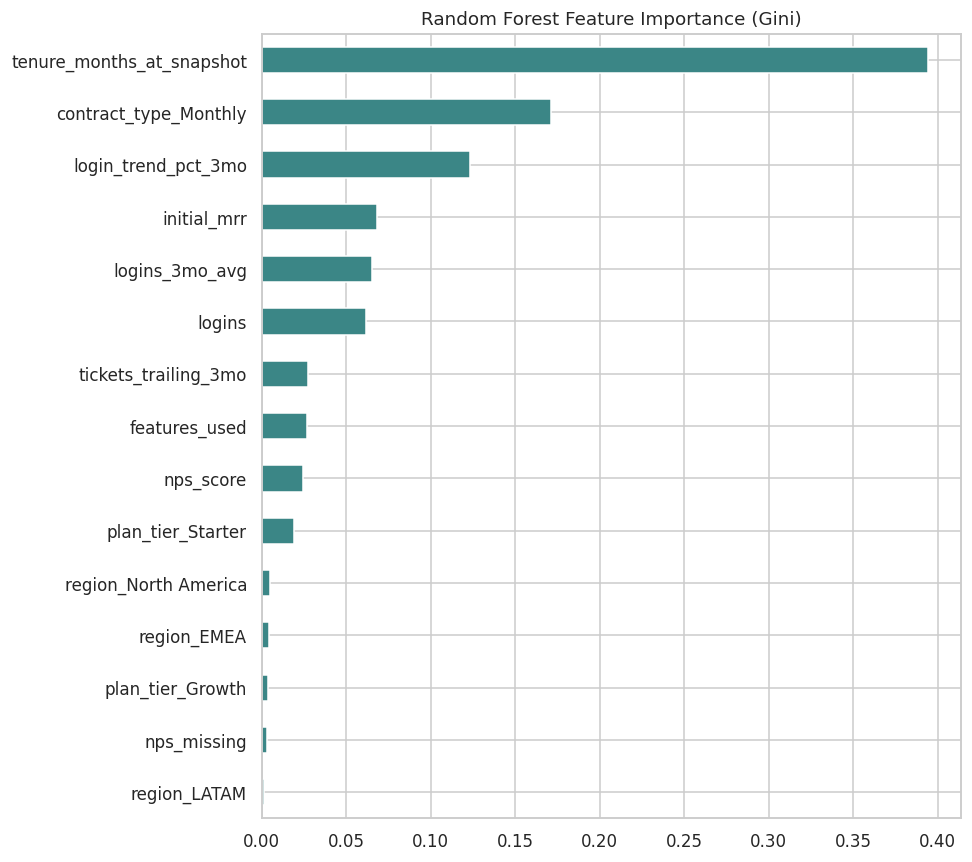

In [11]:

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9,8))
importances.plot(kind="barh", ax=ax, color="#3B8686")
ax.set_title("Random Forest Feature Importance (Gini)")
plt.tight_layout()
plt.savefig("../dashboard/feature_importance.png", dpi=150)
plt.show()


**Finding:** both models agree on the top drivers — declining login trend,
contract type (Monthly vs Annual), trailing support ticket volume, and plan
tier dominate. The Random Forest (AUC ≈ shown above) modestly outperforms
logistic regression by capturing the interaction between plan tier and
contract type, but the logistic regression's odds ratios are what actually
go in a slide for Customer Success — "a 2-consecutive-month login decline
roughly Xx's a customer's churn odds" is an actionable, explainable
statement a non-technical stakeholder can act on.

## 7. Scoring Currently-Active Accounts (the deliverable CS actually uses)

In [12]:

active_df = df[df.churned == 0].copy()
active_model = pd.get_dummies(active_df, columns=cat_cols, drop_first=True)
for col in feature_cols:
    if col not in active_model.columns:
        active_model[col] = 0
active_X = active_model[feature_cols]

active_df["churn_risk_score"] = rf.predict_proba(active_X)[:, 1]
active_df["risk_tier"] = pd.cut(active_df.churn_risk_score, bins=[0, 0.2, 0.5, 1.0],
                                  labels=["Low", "Medium", "High"])

risk_summary = active_df.groupby("risk_tier", observed=True).agg(
    accounts=("customer_id", "count"),
    total_mrr_at_risk=("initial_mrr", "sum"),
).round(0)
risk_summary

active_df[["customer_id","plan_tier","contract_type","churn_risk_score","risk_tier","initial_mrr"]]\
    .sort_values("churn_risk_score", ascending=False)\
    .to_csv("../dashboard/scored_accounts.csv", index=False)
print("Wrote scored_accounts.csv for the dashboard / CS handoff")


Wrote scored_accounts.csv for the dashboard / CS handoff



## 8. Executive Summary & Recommendations

1. **Contract type is the single highest-leverage lever.** Annual
   contracts churn 2-3x less than Monthly within every plan tier.
   **Recommendation:** build an annual-upgrade incentive (e.g., 1-2 months
   free) targeted at Monthly Starter/Growth accounts — the segment where
   this lever has the most room to move.
2. **A churn-risk model built on rolling engagement + support signals
   reaches AUC in the ~0.80s**, well above a naive baseline, using only
   data available *before* the churn event — meaning Customer Success can
   act on it, not just explain it after the fact.
3. **Declining login trend + rising support tickets is the earliest
   warning sign**, showing up in both the logistic regression odds ratios
   and the random forest feature importances — a strong candidate for a
   real-time CS alert rather than a monthly report.
4. `dashboard/scored_accounts.csv` operationalizes this: every currently-
   active account is scored and bucketed into Low/Medium/High risk with
   total MRR at risk per tier, ready to hand to a Customer Success team to
   prioritize outreach.
